In [1]:
import pandas as pd
from pathlib import Path

# Load the raw HR dataset
file_path = Path("../data/raw/IBM-HR-Analytics-Employee-Attrition.csv")
df = pd.read_csv(file_path)

# Inspect the dataset
print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Rows and columns: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [2]:
# 1. Dataset size
print("Dataset shape:", df.shape)

# 2. Column names and data types
print("\n--- Data Types ---")
df.info()

# 3. Missing values
print("\n--- Missing Values ---")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing_Values")
)

# 4. Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate EmployeeNumber:",
      df["EmployeeNumber"].duplicated().sum())

# 5. Attrition distribution
print("\n--- Employee Attrition ---")
display(df["Attrition"].value_counts())

# 6. Constant columns
constant_cols = [
    col for col in df.columns
    if df[col].nunique(dropna=False) == 1
]
print("\nConstant columns:", constant_cols)

Dataset shape: (1470, 35)

--- Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 n

,Missing_Values
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0



Duplicate rows: 0
Duplicate EmployeeNumber: 0

--- Employee Attrition ---


Attrition
No     1233
Yes     237
Name: count, dtype: int64


Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


In [3]:
# Create a separate cleaned copy
df_clean = df.copy()

# Remove unnecessary whitespace from text columns
text_cols = df_clean.select_dtypes(include="object").columns

for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

# Remove constant columns and the unique employee identifier
columns_to_drop = [
    "EmployeeCount",
    "EmployeeNumber",
    "Over18",
    "StandardHours"
]

df_clean = df_clean.drop(
    columns=columns_to_drop,
    errors="ignore"
)

# Validate the cleaned dataset
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Missing values:", df_clean.isna().sum().sum())
print("Remaining columns:", len(df_clean.columns))

# Check attrition distribution
print("\nAttrition distribution:")
display(df_clean["Attrition"].value_counts())

# Save cleaned dataset
output_path = Path(
    "../data/processed/HR-Employee-Attrition-Cleaned.csv"
)

df_clean.to_csv(output_path, index=False)

print("\nCleaned dataset saved successfully!")
print("File location:", output_path.resolve())

Original shape: (1470, 35)
Cleaned shape: (1470, 31)
Duplicate rows: 0
Missing values: 0
Remaining columns: 31

Attrition distribution:


Attrition
No     1233
Yes     237
Name: count, dtype: int64


Cleaned dataset saved successfully!
File location: C:\Users\Ayushman Panthri\OneDrive\Desktop\hr_employee_attrition_project\data\processed\HR-Employee-Attrition-Cleaned.csv


In [4]:
# Overall employee attrition rate
total_employees = len(df_clean)
employees_left = (df_clean["Attrition"] == "Yes").sum()
employees_stayed = (df_clean["Attrition"] == "No").sum()

attrition_rate = employees_left / total_employees * 100

print("Total Employees:", total_employees)
print("Employees Who Left:", employees_left)
print("Employees Who Stayed:", employees_stayed)
print(f"Overall Attrition Rate: {attrition_rate:.2f}%")


# Attrition by department
department_analysis = (
    df_clean.groupby("Department")
    .agg(
        Total_Employees=("Attrition", "size"),
        Employees_Left=(
            "Attrition",
            lambda x: (x == "Yes").sum()
        ),
        Attrition_Rate_Percent=(
            "Attrition",
            lambda x: (x == "Yes").mean() * 100
        )
    )
    .reset_index()
    .sort_values("Attrition_Rate_Percent", ascending=False)
)

print("\n--- Attrition by Department ---")
display(department_analysis.round(2))


# Attrition by overtime
overtime_analysis = (
    df_clean.groupby("OverTime")
    .agg(
        Total_Employees=("Attrition", "size"),
        Employees_Left=(
            "Attrition",
            lambda x: (x == "Yes").sum()
        ),
        Attrition_Rate_Percent=(
            "Attrition",
            lambda x: (x == "Yes").mean() * 100
        )
    )
    .reset_index()
    .sort_values("Attrition_Rate_Percent", ascending=False)
)

print("\n--- Attrition by Overtime ---")
display(overtime_analysis.round(2))

Total Employees: 1470
Employees Who Left: 237
Employees Who Stayed: 1233
Overall Attrition Rate: 16.12%

--- Attrition by Department ---


,Department,Total_Employees,Employees_Left,Attrition_Rate_Percent
2,Sales,446,92,20.63
0,Human Resources,63,12,19.05
1,Research & Development,961,133,13.84



--- Attrition by Overtime ---


,OverTime,Total_Employees,Employees_Left,Attrition_Rate_Percent
1,Yes,416,127,30.53
0,No,1054,110,10.44


In [5]:
# 1. Attrition by Job Role
jobrole_analysis = (
    df_clean.groupby("JobRole")
    .agg(
        Total_Employees=("Attrition", "size"),
        Employees_Left=(
            "Attrition",
            lambda x: x.eq("Yes").sum()
        ),
        Attrition_Rate_Percent=(
            "Attrition",
            lambda x: x.eq("Yes").mean() * 100
        )
    )
    .reset_index()
    .sort_values("Attrition_Rate_Percent", ascending=False)
)

print("--- Attrition by Job Role ---")
display(jobrole_analysis.round(2))


# 2. Attrition by Job Satisfaction (scale: 1 to 4)
satisfaction_analysis = (
    df_clean.groupby("JobSatisfaction")
    .agg(
        Total_Employees=("Attrition", "size"),
        Employees_Left=(
            "Attrition",
            lambda x: x.eq("Yes").sum()
        ),
        Attrition_Rate_Percent=(
            "Attrition",
            lambda x: x.eq("Yes").mean() * 100
        )
    )
    .reset_index()
    .sort_values("JobSatisfaction")
)

print("--- Attrition by Job Satisfaction ---")
display(satisfaction_analysis.round(2))


# 3. Create monthly income bands
df_clean["Salary_Band"] = pd.cut(
    df_clean["MonthlyIncome"],
    bins=[0, 3000, 5000, 8000, 20000],
    labels=[
        "Low (≤3,000)",
        "Lower-middle (3,001–5,000)",
        "Upper-middle (5,001–8,000)",
        "High (>8,000)"
    ],
    include_lowest=True
)

salary_analysis = (
    df_clean.groupby("Salary_Band", observed=False)
    .agg(
        Total_Employees=("Attrition", "size"),
        Employees_Left=(
            "Attrition",
            lambda x: x.eq("Yes").sum()
        ),
        Attrition_Rate_Percent=(
            "Attrition",
            lambda x: x.eq("Yes").mean() * 100
        )
    )
    .reset_index()
)

print("--- Attrition by Monthly Income Band ---")
display(salary_analysis.round(2))

--- Attrition by Job Role ---


,JobRole,Total_Employees,Employees_Left,Attrition_Rate_Percent
8,Sales Representative,83,33,39.76
2,Laboratory Technician,259,62,23.94
1,Human Resources,52,12,23.08
7,Sales Executive,326,57,17.48
6,Research Scientist,292,47,16.10
4,Manufacturing Director,145,10,6.90
0,Healthcare Representative,131,9,6.87
3,Manager,102,5,4.90
5,Research Director,80,2,2.50


--- Attrition by Job Satisfaction ---


,JobSatisfaction,Total_Employees,Employees_Left,Attrition_Rate_Percent
0,1,289,66,22.84
1,2,280,46,16.43
2,3,442,73,16.52
3,4,459,52,11.33


--- Attrition by Monthly Income Band ---


,Salary_Band,Total_Employees,Employees_Left,Attrition_Rate_Percent
0,"Low (≤3,000)",395,113,28.61
1,"Lower-middle (3,001–5,000)",354,50,14.12
2,"Upper-middle (5,001–8,000)",340,34,10.00
3,"High (>8,000)",381,40,10.50


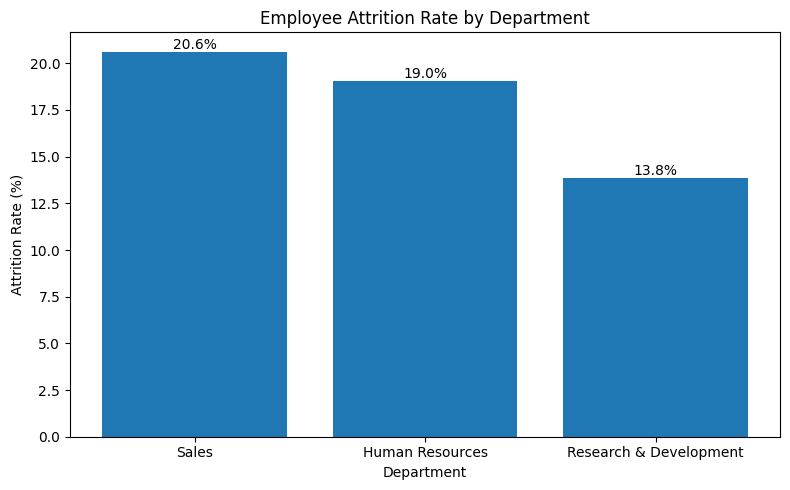

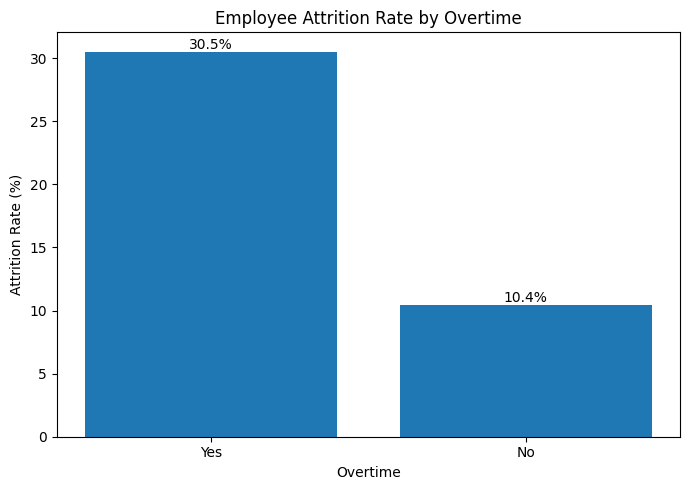

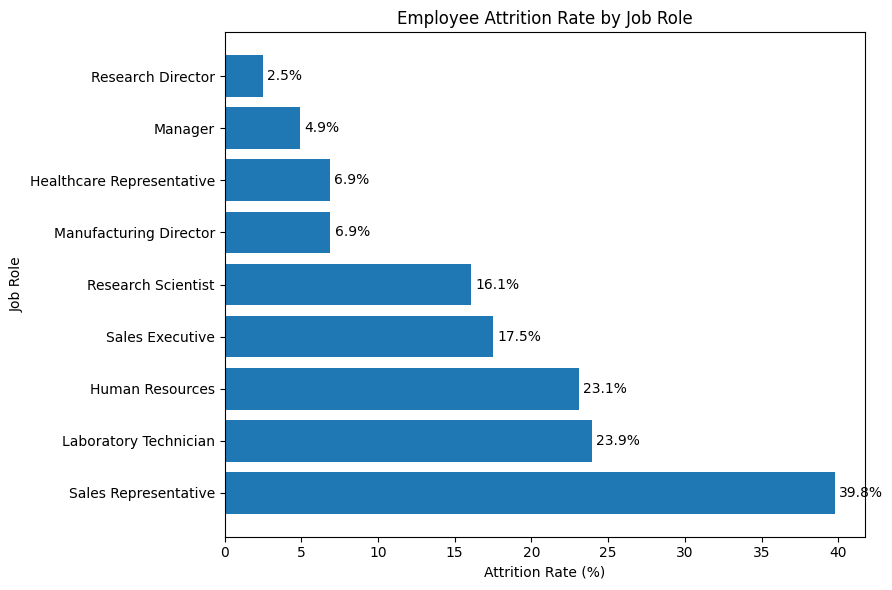

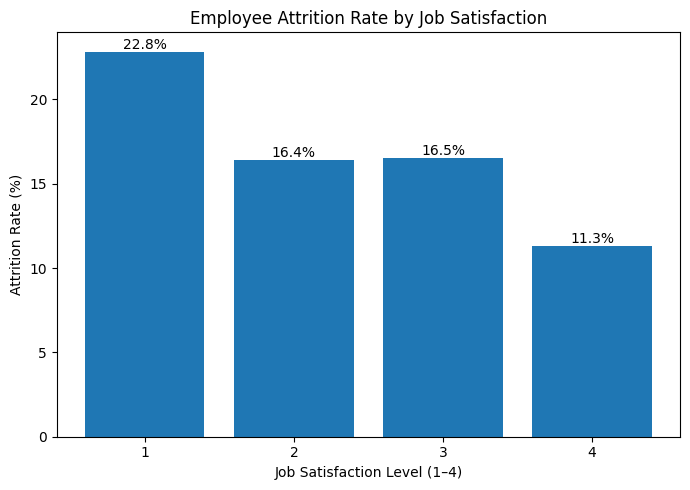

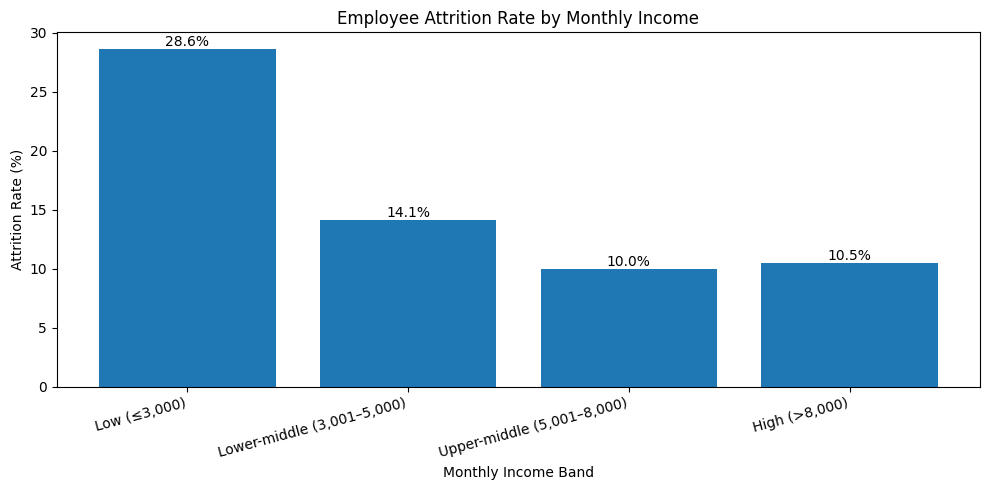

In [6]:
import matplotlib.pyplot as plt

# 1. Attrition by Department
plt.figure(figsize=(8, 5))
bars = plt.bar(
    department_analysis["Department"],
    department_analysis["Attrition_Rate_Percent"]
)
plt.title("Employee Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.bar_label(bars, fmt="%.1f%%")
plt.tight_layout()
plt.show()


# 2. Attrition by Overtime
plt.figure(figsize=(7, 5))
bars = plt.bar(
    overtime_analysis["OverTime"],
    overtime_analysis["Attrition_Rate_Percent"]
)
plt.title("Employee Attrition Rate by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")
plt.bar_label(bars, fmt="%.1f%%")
plt.tight_layout()
plt.show()


# 3. Attrition by Job Role
plt.figure(figsize=(9, 6))
bars = plt.barh(
    jobrole_analysis["JobRole"],
    jobrole_analysis["Attrition_Rate_Percent"]
)
plt.title("Employee Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.tight_layout()
plt.show()


# 4. Attrition by Job Satisfaction
plt.figure(figsize=(7, 5))
bars = plt.bar(
    satisfaction_analysis["JobSatisfaction"].astype(str),
    satisfaction_analysis["Attrition_Rate_Percent"]
)
plt.title("Employee Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction Level (1–4)")
plt.ylabel("Attrition Rate (%)")
plt.bar_label(bars, fmt="%.1f%%")
plt.tight_layout()
plt.show()


# 5. Attrition by Monthly Income Band
plt.figure(figsize=(10, 5))
bars = plt.bar(
    salary_analysis["Salary_Band"].astype(str),
    salary_analysis["Attrition_Rate_Percent"]
)
plt.title("Employee Attrition Rate by Monthly Income")
plt.xlabel("Monthly Income Band")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=15, ha="right")
plt.bar_label(bars, fmt="%.1f%%")
plt.tight_layout()
plt.show()